![Ticket 2 Ride Banner](images/banner.png)

# Ticket 2 ride by ram and fati

## Explore and check the data first

In [1]:
import pandas as pd

df = pd.read_csv("data/passagierfrequenz.csv", sep=";")

df.head()

,Code_Codice,UIC,Bahnhof_Gare_Stazione,Kt_Ct_Cantone,ISB_GI,Jahr_Annee_Anno,DTV_TJM_TGM,DWV_TMJO_TFM,DNWV_TMJNO_TMGNL,EVU_EF_ITF,Bemerkungen,Remarques,Note,Remarks,LOD,geopos
0,AA,8502113.0,Aarau,AG,SBB,2018,37900.0,44800.0,22700.0,SBB,Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
1,AA,8502113.0,Aarau,AG,SBB,2023,37700.0,43400.0,24700.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
2,AA,8502113.0,Aarau,AG,SBB,2024,39000.0,45300.0,24800.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
3,AA,8502113.0,Aarau,AG,SBB,2025,40100.0,46600.0,25700.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
4,AAT,8503124.0,Aathal,ZH,SBB,2022,690.0,750.0,570.0,SBB,NaN,NaN,NaN,NaN,http://lod.opentransportdata.swiss/didok/didok85,"47.3359591338364, 8.765625135347072"


In [2]:
df.shape

(5724, 16)

In [3]:
df.columns.tolist()

['Code_Codice',
 'UIC',
 'Bahnhof_Gare_Stazione',
 'Kt_Ct_Cantone',
 'ISB_GI',
 'Jahr_Annee_Anno',
 'DTV_TJM_TGM',
 'DWV_TMJO_TFM',
 'DNWV_TMJNO_TMGNL',
 'EVU_EF_ITF',
 'Bemerkungen',
 'Remarques',
 'Note',
 'Remarks',
 'LOD',
 'geopos']

In [4]:
df["Jahr_Annee_Anno"].unique()

array([2018, 2023, 2024, 2025, 2022])

In [5]:
df.isnull().sum()

Code_Codice                 0
UIC                         0
Bahnhof_Gare_Stazione       0
Kt_Ct_Cantone               0
ISB_GI                      0
Jahr_Annee_Anno             0
DTV_TJM_TGM                 0
DWV_TMJO_TFM                0
DNWV_TMJNO_TMGNL            0
EVU_EF_ITF                  0
Bemerkungen              5057
Remarques                5057
Note                     5057
Remarks                  5057
LOD                        15
geopos                     15
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.duplicated(
    subset=["UIC", "Jahr_Annee_Anno"]
).sum()

np.int64(0)

In [8]:
df_2025 = df[df["Jahr_Annee_Anno"] == 2025]

df_2025.shape

(1095, 16)

In [9]:
top10 = df_2025.sort_values(
    by="DTV_TJM_TGM",
    ascending=False
).head(10)

top10[["Bahnhof_Gare_Stazione", "DTV_TJM_TGM"]]

,Bahnhof_Gare_Stazione,DTV_TJM_TGM
5712,Zürich HB,449800.0
105,Bern,177000.0
4038,Luzern,108800.0
3562,Basel SBB,103800.0
2238,Winterthur,103800.0
4021,Lausanne,97500.0
5707,Zürich Oerlikon,86200.0
4914,Genève,83100.0
744,Olten,81600.0
1140,Zürich Stadelhofen,75200.0


## 1. Find the busiest stations

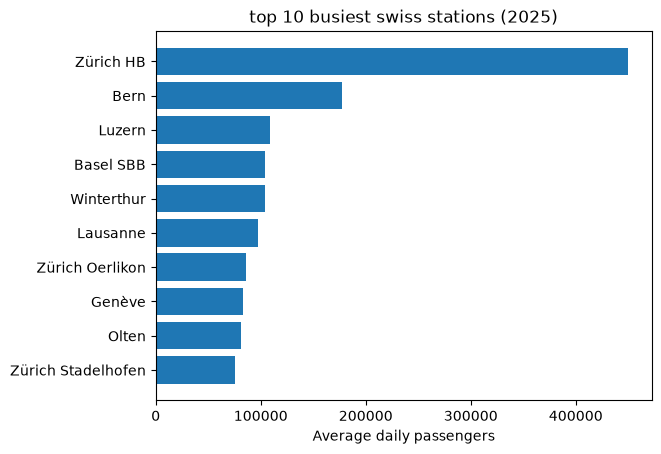

In [10]:
import matplotlib.pyplot as plt
plt.barh(
    top10["Bahnhof_Gare_Stazione"],
    top10["DTV_TJM_TGM"]
)
plt.xlabel("Average daily passengers") 
plt.title("top 10 busiest swiss stations (2025)")
plt.gca().invert_yaxis()

plt.show()

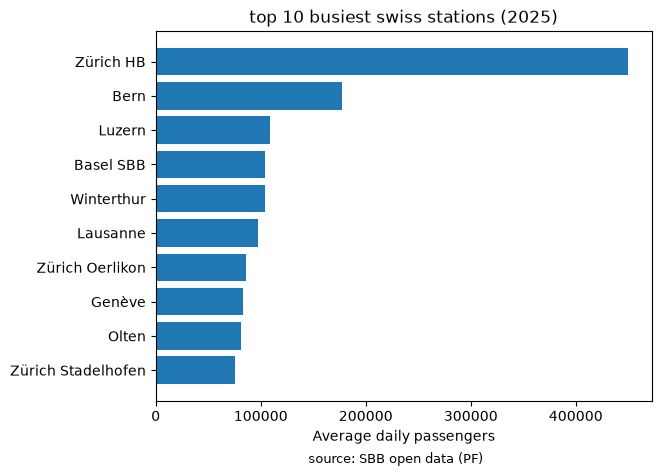

In [11]:
import matplotlib.pyplot as plt
plt.barh(
    top10["Bahnhof_Gare_Stazione"],
    top10["DTV_TJM_TGM"]
)
plt.xlabel("Average daily passengers") 
plt.title("top 10 busiest swiss stations (2025)")
plt.gca().invert_yaxis()

#add our source 
plt.figtext(
    0.5, -0.02,
    "source: SBB open data (PF)",
    ha="center",
    fontsize=9
) 
plt.show()


## 2. Cornavin's story

In [12]:
geneva = df[df["Bahnhof_Gare_Stazione"]=="Genève"]
geneva = geneva.sort_values("Jahr_Annee_Anno") 
geneva[["Jahr_Annee_Anno","DTV_TJM_TGM"]]

,Jahr_Annee_Anno,DTV_TJM_TGM
2647,2018,60500.0
3818,2022,66900.0
2648,2023,79500.0
364,2024,80600.0
4914,2025,83100.0


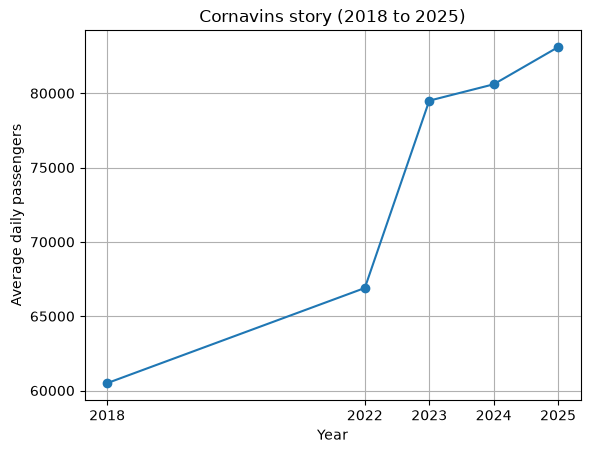

In [13]:
import matplotlib.pyplot as plt

plt.plot(
    geneva["Jahr_Annee_Anno"],
    geneva["DTV_TJM_TGM"],
    marker="o"
)

plt.title("Cornavins story (2018 to 2025)")
plt.xlabel("Year") 
plt.ylabel("Average daily passengers")
plt.xticks(geneva["Jahr_Annee_Anno"])
plt.grid(True)
plt.show()

In [14]:
geneva["Growth%"
    ] = geneva["DTV_TJM_TGM"].pct_change() * 100
geneva[["Jahr_Annee_Anno", "DTV_TJM_TGM", "Growth%"]]

,Jahr_Annee_Anno,DTV_TJM_TGM,Growth%
2647,2018,60500.0,NaN
3818,2022,66900.0,10.578512
2648,2023,79500.0,18.834081
364,2024,80600.0,1.383648
4914,2025,83100.0,3.101737


### Findings 
Passenger traffic at Cornavin increased from 60k average daily passengers in 2018 to 83k in 2025, that is a huge growth and it's almost 37,4% average increase. Also, the largest increase from one year to another happened in the year 23-23 (with +18.83%). Growth then slowed to 1.38% in 2024 and then reached 3.10% in 2025.
We couldn't analyse 2019, 2020, 2021 because the dataset didnt include them (they're missing). 

## Scénario 3 : The Swiss Rail Map

In [15]:
# on charge pandas (pd) pour les tableaux et matplotlib (plt) pour les graphiques
import pandas as pd
import matplotlib.pyplot as plt
# on lit le fichier passagierfrequenz.csv (ses colonnes sont séparées par des ;)
df = pd.read_csv("data/passagierfrequenz.csv", sep=";")


In [16]:
# on garde seulement les lignes de l'année 2025
df_2025 = df[df["Jahr_Annee_Anno"] == 2025]
df_2025.shape

(1095, 16)

In [17]:
# combien de gares n'ont pas de coordonnées ?
df_2025["geopos"].isna().sum()

np.int64(3)

In [18]:
# on enlève les gares qui n'ont pas de coordonnées en regardant la colonne geopos
df_2025 = df_2025.dropna(subset=["geopos"])
df_2025.shape

(1092, 16)

In [19]:
# on coupe geopos à la virgule pour toutes les gares et après on met latitude et longitude dans deux colonnes (0 et 1)
coord = df_2025["geopos"].str.split(",", expand=True)
coord.head()

,0,1
3,47.39135951416977,8.051273718700699
5,46.31234824494208,7.8441670280993065
7,47.320268469495055,7.908222606719322
24,46.47575352079991,6.399697079747334
32,47.510587732978976,9.433358582621896


In [20]:
# on transforme les textes en nombres et on crée les colonnes lat et lon. Ensuite vérification.
df_2025["lat"] = coord[0].astype(float)
df_2025["lon"] = coord[1].astype(float)
df_2025[["Bahnhof_Gare_Stazione", "lat", "lon"]].head()

,Bahnhof_Gare_Stazione,lat,lon
3,Aarau,47.391360,8.051274
5,Ausserberg,46.312348,7.844167
7,Aarburg-Oftringen,47.320268,7.908223
24,Allaman,46.475754,6.399697
32,Arbon,47.510588,9.433359


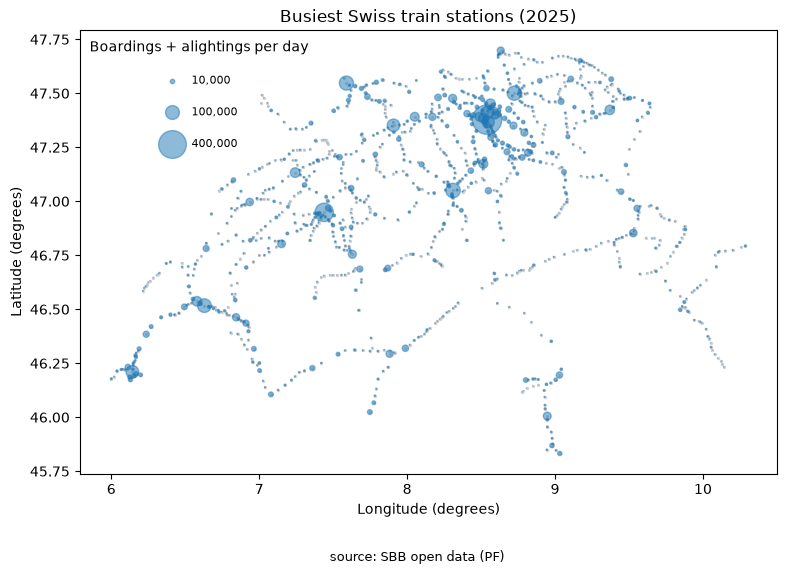

In [21]:
# une feuille de dessin plus grande (largeur 9, hauteur 6)
plt.figure(figsize=(9, 6))

# fond : toutes les gares en petits points gris, pour voir le réseau
plt.scatter(df_2025["lon"], df_2025["lat"], s=2, color="lightgray")
# par-dessus : taille du point = montées et descentes par jour, divisées par 1000
# alpha=0.5 rend les bulles transparentes, pour voir celles qui se chevauchent
plt.scatter(df_2025["lon"], df_2025["lat"], s=df_2025["DTV_TJM_TGM"] / 1000, color="tab:blue", alpha=0.5)

# légende des tailles, avec 3 bulles d'exemple qui ne sont pas placées sur la carte
plt.scatter([], [], s=10000 / 1000, color="tab:blue", alpha=0.5, label="10,000")
plt.scatter([], [], s=100000 / 1000, color="tab:blue", alpha=0.5, label="100,000")
plt.scatter([], [], s=400000 / 1000, color="tab:blue", alpha=0.5, label="400,000")
# légende sans cadre, avec un texte plus petit
plt.legend(title="Boardings + alightings per day", loc="upper left", fontsize=8, title_fontsize=10, labelspacing=1.8, frameon=False)

# vraies proportions de la Suisse (1 degré nord-sud est 1,46 fois plus long qu'1 degré est-ouest)
plt.gca().set_aspect(1.46)

# titre et noms des axes
plt.title("Busiest Swiss train stations (2025)")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
# la source sous la carte
plt.figtext(0.5, -0.02, "source: SBB open data (PF)", ha="center", fontsize=9)
plt.show()

### What we found
Les plus grosses bulles se trouvent surtout en Suisse alémanique, autour de Zurich, et huit des dix gares les plus fréquentées sont alémaniques. Zürich HB est très loin devant, avec 449 800 montées et descentes par jour, environ 5 fois plus que Genève (83 100). La Suisse romande a moins de grosses bulles, même si Lausanne et Genève sont dans le top 10, et au Tessin et dans les Alpes on ne voit presque que de petites gares.

Attention, on compte des montées et des descentes, pas des voyageurs. Une personne qui change de train à Zurich est comptée deux fois, ce qui grossit les grandes gares de correspondance.